In [3]:
import ast
import pandas as pd

# Path ke file dataset
train_path = "../../../data/raw/semeval2021/data/tsd_train.csv"
trial_path = "../../../data/raw/semeval2021/data/tsd_trial.csv"
test_path  = "../../../data/raw/semeval2021/data/tsd_test.csv"

# Baca CSV dengan converter ast.literal_eval
df_train = pd.read_csv(train_path, converters={"spans": ast.literal_eval})
df_trial = pd.read_csv(trial_path, converters={"spans": ast.literal_eval})
df_test  = pd.read_csv(test_path, converters={"spans": ast.literal_eval})

print(f"Data Train Counts : {len(df_train)}")
print(f"Data Trial Counts : {len(df_trial)}")
print(f"Data Test Counts  : {len(df_test)}")
# Cek tipe data kolom spans
print("Tipe data spans:", type(df_train["spans"].iloc[0])) # Output: <class 'list'>
print(">>> Dataframe train:")
df_train.head()

Data Train Counts : 7939
Data Trial Counts : 690
Data Test Counts  : 2000
Tipe data spans: <class 'list'>
>>> Dataframe train:


,spans,text
0,"[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,...",Another violent and aggressive immigrant killi...
1,"[33, 34, 35, 36, 37, 38, 39]","I am 56 years old, I am not your fucking junio..."
2,"[0, 1, 2, 3]","Damn, a whole family. Sad indeed."
3,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]",What a knucklehead. How can anyone not know th...
4,"[32, 33, 34, 35, 36, 37, 38]","""who do you think should do the killing?""\n\nA..."


In [4]:
from itertools import groupby
from operator import itemgetter

def extract_toxic_words(text, spans):
    """
    Mengubah list indeks karakter [15, 16, 17, 18, 19]
    menjadi teks potongan aslinya.
    """
    if not spans:
        return []

    # Kelompokkan indeks yang berurutan
    words = []
    for _, g in groupby(enumerate(sorted(spans)), lambda ix: ix[0] - ix[1]):
        group = list(map(itemgetter(1), g))
        start, end = group[0], group[-1] + 1
        words.append(text[start:end])
    return words

# Contoh melihat 5 sampel pertama beserta kata toksiknya
for i in range(5):
    row = df_train.iloc[i]
    toxic_words = extract_toxic_words(row["text"], row["spans"])

    print(f">>> Data ke-{i+1}")
    print(f"Teks Asli   : {row['text']}")
    print(f"Spans Indeks: {row['spans'][:10]}... (Total {len(row['spans'])} karakter)" if len(row['spans']) > 10 else f"Spans: {row['spans']}")
    print(f"Kata Toksik : {toxic_words}")
    print()

>>> Data ke-1
Teks Asli   : Another violent and aggressive immigrant killing a innocent and intelligent US Citizen.... Sarcasm
Spans Indeks: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17]... (Total 32 karakter)
Kata Toksik : ['violent and aggressive immigrant']

>>> Data ke-2
Teks Asli   : I am 56 years old, I am not your fucking junior pal. What you are saying makes no sense. I don't know what you are basing this on. The cheap black market crap is still coming up from Mexican nationals, and the good stuff from BC and Humbolt.  The I5 corridor is still just as busy, and they are still making a ton of money. Nothing has really changed except that the legal market has made it easy for anyone of legal age to buy it.  And the legal market is controlled by corporate growers with million dollar facilities, or a co-op of smaller growers. The Federal government "war on drugs" really has no impact on the legal market in Oregon. I don't see any glutton of weed, whatever that means.
Spans: [33, 34, 35, 3

In [5]:
import sys
from pathlib import Path

sys.path.insert(0, "../../../data/raw/semeval2021/evaluation")
from fix_spans import _contiguous_ranges, fix_spans

EDA_DIR = Path("../../../outputs/task_3/results/eda")
EDA_DIR.mkdir(parents=True, exist_ok=True)

splits = {"train": df_train, "trial": df_trial, "test": df_test}
rows = []
for name, df in splits.items():
    assert df["text"].notna().all() and df["spans"].notna().all()
    assert all(0 <= i < len(t) for t, s in zip(df["text"], df["spans"]) for i in s)
    df["fixed_spans"] = [fix_spans(s, t) for t, s in zip(df["text"], df["spans"])]
    ranges = [_contiguous_ranges(s) for s in df["fixed_spans"]]
    n = len(df)
    rows.append({
        "split": name,
        "rows": n,
        "dup_text": int(df["text"].duplicated().sum()),
        "empty_raw_%": round(100 * (df["spans"].str.len() == 0).mean(), 2),
        "empty_fixed_%": round(100 * (df["fixed_spans"].str.len() == 0).mean(), 2),
        "single_span_%": round(100 * sum(len(r) == 1 for r in ranges) / n, 2),
        "multi_span_%": round(100 * sum(len(r) >= 2 for r in ranges) / n, 2),
        "changed_by_fix": sum(sorted(a) != sorted(b) for a, b in zip(df["spans"], df["fixed_spans"])),
    })

summary_df = pd.DataFrame(rows)
summary_df.to_csv(EDA_DIR / "summary.csv", index=False)
summary_df

,split,rows,dup_text,empty_raw_%,empty_fixed_%,single_span_%,multi_span_%,changed_by_fix
0,train,7939,0,6.11,6.15,67.68,26.17,32
1,trial,690,0,6.23,6.23,65.22,28.55,4
2,test,2000,0,19.70,19.70,70.35,9.95,1


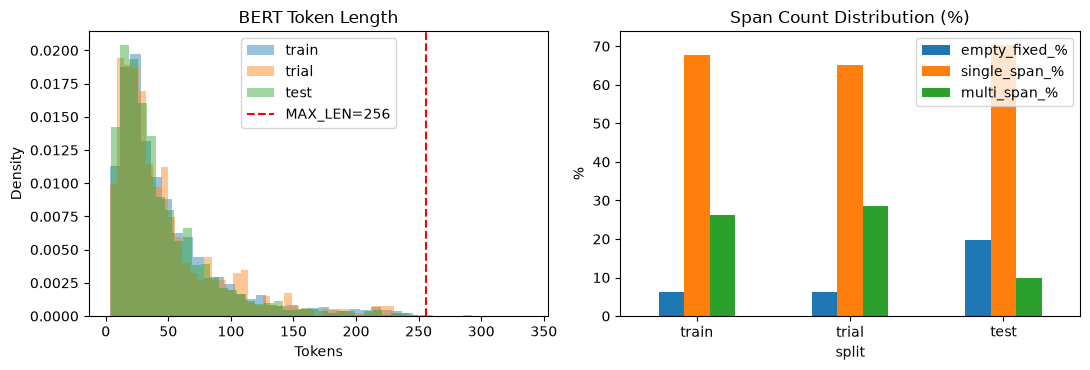

,split,char_med,char_p99,char_max,word_med,word_p99,word_max,bert_tok_med,bert_tok_p95,bert_tok_p99,bert_tok_max,gt_256_%
0,train,136,992,1000,24,171,192,34,149,222,337,0.13
1,trial,134,982,998,24,173,182,33,142,218,236,0.00
2,test,129,947,1000,23,157,186,32,128,208,293,0.05


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased", use_fast=True)
len_stats = []
tok_lens = {}
for name, df in splits.items():
    texts = df["text"].tolist()
    tok_lens[name] = [len(ids) for ids in tok(texts, truncation=False)["input_ids"]]
    c = df["text"].str.len()
    w = df["text"].str.split().str.len()
    t = pd.Series(tok_lens[name])
    len_stats.append({
        "split": name,
        "char_med": int(c.median()), "char_p99": int(c.quantile(0.99)), "char_max": int(c.max()),
        "word_med": int(w.median()), "word_p99": int(w.quantile(0.99)), "word_max": int(w.max()),
        "bert_tok_med": int(t.median()), "bert_tok_p95": int(t.quantile(0.95)),
        "bert_tok_p99": int(t.quantile(0.99)), "bert_tok_max": int(t.max()),
        "gt_256_%": round(100 * (t > 256).mean(), 2),
    })

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, lens in tok_lens.items():
    ax[0].hist(lens, bins=40, alpha=0.45, density=True, label=name)
ax[0].axvline(256, color="r", ls="--", label="MAX_LEN=256")
ax[0].set(title="BERT Token Length", xlabel="Tokens", ylabel="Density")
ax[0].legend()

summary_df.set_index("split")[["empty_fixed_%", "single_span_%", "multi_span_%"]].plot(kind="bar", ax=ax[1])
ax[1].set(title="Span Count Distribution (%)", ylabel="%")
ax[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(EDA_DIR / "distributions.png", dpi=150)
plt.show()
pd.DataFrame(len_stats)

In [7]:
# Boundary noise (spans vs fix_spans) & partial-word spans
changed = df_train[df_train["spans"].map(sorted) != df_train["fixed_spans"].map(sorted)]
print(f"Train berubah pasca fix_spans: {len(changed)}, menjadi kosong: {(changed['fixed_spans'].str.len() == 0).sum()}")
for _, r in changed.head(5).iterrows():
    print("RAW:", extract_toxic_words(r["text"], r["spans"]), "-> FIXED:", extract_toxic_words(r["text"], r["fixed_spans"]))

partial = 0
total_ranges = 0
for t, fs in zip(df_train["text"], df_train["fixed_spans"]):
    for s, e in _contiguous_ranges(fs):
        total_ranges += 1
        left_cut = s > 0 and t[s].isalnum() and t[s - 1].isalnum()
        right_cut = e + 1 < len(t) and t[e].isalnum() and t[e + 1].isalnum()
        partial += (left_cut or right_cut)
print(f"Partial-word spans di train: {partial}/{total_ranges} ({100 * partial / total_ranges:.2f}%)")

Train berubah pasca fix_spans: 32, menjadi kosong: 3
RAW: ['to', 'trash-talk'] -> FIXED: ['trash-talk']
RAW: ['He is such an ass', ' i hope he knows the depth of disgust he is creating for himself and his most beloved Justin trudea', 'Or will they  ask him low ball questions about the weather to save him embarrassment of looking like an idiot'] -> FIXED: ['He is such an ass', 'i hope he knows the depth of disgust he is creating for himself and his most beloved Justin trudea', 'Or will they  ask him low ball questions about the weather to save him embarrassment of looking like an idiot']
RAW: ['Most of trump supporters in red states rely on the government in on way or another for support and there is no way they voted for trump to cut those programs.  They want more government support, not less.  \ntrump promises the moon and only stupid people believe '] -> FIXED: ['Most of trump supporters in red states rely on the government in on way or another for support and there is no way they v

In [8]:
import re
from collections import Counter

phrases = Counter()
words = Counter()
for t, fs in zip(df_train["text"], df_train["fixed_spans"]):
    for seg in extract_toxic_words(t, fs):
        phrases[seg.lower()] += 1
        words.update(re.findall(r"[a-z']+", seg.lower()))

t1_toxic = {w.strip().lower() for w in Path("../../../data/processed/task_1/resources/toxic.txt").read_text(encoding="utf-8").splitlines() if w.strip()}
top20_words = [w for w, _ in words.most_common(20)]
overlap = [w for w in top20_words if w in t1_toxic]
print("Top-20 span phrases:", phrases.most_common(20))
print("Top-20 single words:", words.most_common(20))
print(f"Overlap Top-20 SemEval vs CONDA/Task1 toxic.txt ({len(overlap)}/20): {overlap}")

Top-20 span phrases: [('stupid', 1116), ('idiot', 595), ('idiots', 384), ('stupidity', 233), ('ignorant', 205), ('dumb', 173), ('moron', 172), ('pathetic', 149), ('fool', 143), ('ridiculous', 115), ('damn', 110), ('idiotic', 109), ('crap', 103), ('fools', 98), ('morons', 93), ('hypocrite', 78), ('loser', 78), ('silly', 58), ('ass', 57), ('shit', 55)]
Top-20 single words: [('stupid', 1242), ('idiot', 671), ('the', 582), ('idiots', 428), ('a', 393), ('and', 352), ('of', 289), ('ignorant', 278), ('stupidity', 278), ('to', 257), ('is', 256), ('you', 229), ('dumb', 219), ('moron', 192), ('pathetic', 185), ('fool', 182), ('are', 179), ('in', 177), ('crap', 151), ('that', 147)]
Overlap Top-20 SemEval vs CONDA/Task1 toxic.txt (6/20): ['stupid', 'idiot', 'idiots', 'dumb', 'moron', 'crap']
